In [1]:
# библиотеки и параметры, общие для обеих задач
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

SEED = 42
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
METRICS = {"classification": ["F1_macro", "Accuracy"], "regression": ["MAE", "RMSE", "R2"]}
PRIMARY = {"classification": "F1_macro", "regression": "MAE"}
VARIANTS = ["dummy", "sklearn", "sklearn+", "own", "own+"]

In [2]:
# читаем исходные таблицы из архивов UCI и явно отделяем цели от признаков
def read_uci_file(archive_name, filename, **read_options):
    url = f"https://archive.ics.uci.edu/static/public/{archive_name}"
    with urlopen(url, timeout=60) as response:
        archive_bytes = response.read()
    with ZipFile(BytesIO(archive_bytes)) as archive:
        member = next(name for name in archive.namelist() if Path(name).name == filename)
        with archive.open(member) as source:
            return pd.read_csv(source, header=None, **read_options)


wifi_columns = [f"signal_{i}" for i in range(1, 8)] + ["room"]
wifi = read_uci_file(
    "422/wireless+indoor+localization.zip", "wifi_localization.txt",
    sep=r"\s+", names=wifi_columns,
)

hardware_features = ["MYCT", "MMIN", "MMAX", "CACH", "CHMIN", "CHMAX"]
hardware_columns = ["vendor", "model", *hardware_features, "PRP", "ERP"]
hardware = read_uci_file(
    "29/computer+hardware.zip", "machine.data", names=hardware_columns,
)

assert wifi.shape == (2000, 8) and hardware.shape == (209, 10)
assert set(wifi["room"]) == {1, 2, 3, 4}
assert not wifi.isna().any().any() and not hardware.isna().any().any()

DATA = {
    "classification": (wifi[wifi_columns[:-1]].to_numpy(dtype=float), wifi["room"].to_numpy()),
    "regression": (hardware[hardware_features].to_numpy(dtype=float), hardware["PRP"].to_numpy(dtype=float)),
}
for task, (X, y) in DATA.items():
    print(f"{TASK_NAMES[task]}: {X.shape[0]} объектов, {X.shape[1]} признаков")

Классификация: 2000 объектов, 7 признаков
Регрессия: 209 объектов, 6 признаков


In [3]:
# преобразуем признаки внутри каждого разбиения и считаем метрики
def transform_features(X_train, X_eval, preparation):
    if preparation == "relative":
        X_train = np.column_stack([X_train, X_train - X_train.max(axis=1, keepdims=True)])
        X_eval = np.column_stack([X_eval, X_eval - X_eval.max(axis=1, keepdims=True)])
    elif preparation == "ratios":
        def with_ratios(X):
            memory_growth = X[:, 2] / np.maximum(X[:, 1], 1)
            cache_share = X[:, 3] / np.maximum(X[:, 2], 1)
            return np.column_stack([X, memory_growth, cache_share])

        X_train, X_eval = with_ratios(X_train), with_ratios(X_eval)
    elif preparation == "log":
        X_train, X_eval = np.log1p(X_train), np.log1p(X_eval)

    if preparation in {"scale", "log", "relative"}:
        scaler = StandardScaler().fit(X_train)
        X_train, X_eval = scaler.transform(X_train), scaler.transform(X_eval)
    return X_train, X_eval


def folds(task, X, y, n_splits, seed):
    splitter_class = StratifiedKFold if task == "classification" else KFold
    return splitter_class(n_splits=n_splits, shuffle=True, random_state=seed).split(X, y)


def predict_on(model, preparation, X_train, y_train, X_eval):
    X_train, X_eval = transform_features(X_train, X_eval, preparation)
    return model.fit(X_train, y_train).predict(X_eval)


def scores(task, y, prediction):
    if task == "classification":
        return {
            "F1_macro": f1_score(y, prediction, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, prediction),
        }
    return {
        "MAE": mean_absolute_error(y, prediction),
        "RMSE": np.sqrt(mean_squared_error(y, prediction)),
        "R2": r2_score(y, prediction),
    }

## Модели

В своей реализации дерево предсказывает остаток PRP или разность между меткой класса и её текущей вероятностью. Для классификации упрощённое обновление идёт по градиенту, поэтому оценки могут отличаться от sklearn

In [4]:
# строим CART по снижению примеси Джини или суммы квадратов ошибок
from dataclasses import dataclass


@dataclass
class Node:
    value: float
    feature: int = -1
    threshold: float = 0.0
    left: object = None
    right: object = None


class CART:
    def __init__(self, task, max_depth=None, min_samples_leaf=1, max_features=None, seed=SEED):
        self.task = task
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.seed = seed

    def fit(self, X, y):
        self.X, self.y = X, y
        self.rng = np.random.default_rng(self.seed)
        if self.task == "classification":
            self.classes, encoded = np.unique(y, return_inverse=True)
            self.targets = np.eye(len(self.classes))[encoded]
        else:
            self.targets = y.reshape(-1, 1)
        self.root = self._grow(np.arange(len(y)), depth=0)
        return self

    def _grow(self, indices, depth):
        count = len(indices)
        targets = self.targets[indices]
        totals = targets.sum(axis=0)
        value = self.classes[totals.argmax()] if self.task == "classification" else totals[0] / count
        node = Node(value)
        min_leaf = self.min_samples_leaf
        if count < 2 * min_leaf or (self.max_depth is not None and depth >= self.max_depth):
            return node
        if np.all(self.y[indices] == self.y[indices[0]]):
            return node

        feature_count = self.X.shape[1]
        features = np.arange(feature_count)
        if self.max_features == "sqrt":
            features = self.rng.permutation(features)[:max(1, int(np.sqrt(feature_count)))]

        parent_quality = np.dot(totals, totals) / count
        best_quality = parent_quality + 1e-12
        best_split = None
        for feature in features:
            order = np.argsort(self.X[indices, feature], kind="stable")
            sorted_indices = indices[order]
            values = self.X[sorted_indices, feature]
            cuts = np.flatnonzero(values[1:] > values[:-1]) + 1
            cuts = cuts[(cuts >= min_leaf) & (cuts <= count - min_leaf)]
            if not len(cuts):
                continue
            left_totals = targets[order].cumsum(axis=0)[cuts - 1]
            right_totals = totals - left_totals
            quality = (left_totals ** 2).sum(axis=1) / cuts
            quality += (right_totals ** 2).sum(axis=1) / (count - cuts)
            best = quality.argmax()
            if quality[best] > best_quality:
                cut = cuts[best]
                best_quality = quality[best]
                threshold = values[cut - 1] + (values[cut] - values[cut - 1]) / 2
                best_split = feature, threshold, sorted_indices[:cut], sorted_indices[cut:]

        if best_split is not None:
            node.feature, node.threshold, left, right = best_split
            node.left = self._grow(left, depth + 1)
            node.right = self._grow(right, depth + 1)
        return node

    def predict(self, X):
        predictions = []
        for row in X:
            node = self.root
            while node.feature >= 0:
                node = node.left if row[node.feature] <= node.threshold else node.right
            predictions.append(node.value)
        return np.asarray(predictions)

In [5]:
# последовательно обучаем неглубокие деревья на антиградиентах функции потерь
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor


class GradientBoosting:
    def __init__(self, task, n_estimators, learning_rate, max_depth, min_samples_leaf):
        self.task = task
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.tree_params = {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf}

    def fit(self, X, y):
        self.rounds = []
        if self.task == "regression":
            self.initial = np.array([y.mean()])
            targets = y[:, None]
        else:
            self.classes, encoded = np.unique(y, return_inverse=True)
            targets = np.eye(len(self.classes))[encoded]
            self.initial = np.log(targets.mean(axis=0))
        raw = np.tile(self.initial, (len(X), 1))

        for _ in range(self.n_estimators):
            if self.task == "regression":
                residuals = targets - raw
            else:
                probabilities = np.exp(raw - raw.max(axis=1, keepdims=True))
                probabilities /= probabilities.sum(axis=1, keepdims=True)
                residuals = targets - probabilities
            trees = []
            for column in range(raw.shape[1]):
                tree = CART("regression", **self.tree_params).fit(X, residuals[:, column])
                raw[:, column] += self.learning_rate * tree.predict(X)
                trees.append(tree)
            self.rounds.append(trees)
        return self

    def predict(self, X):
        raw = np.tile(self.initial, (len(X), 1))
        for trees in self.rounds:
            for column, tree in enumerate(trees):
                raw[:, column] += self.learning_rate * tree.predict(X)
        if self.task == "regression":
            return raw[:, 0]
        return self.classes[raw.argmax(axis=1)]


def library_model(task, **params):
    estimator = GradientBoostingClassifier if task == "classification" else GradientBoostingRegressor
    return estimator(random_state=SEED, **params)


def own_model(task, **params):
    return GradientBoosting(task, **params)

In [6]:
# проверяем темп обучения, число шагов, глубину деревьев и дополнительные признаки
LAB = 5
base = {"n_estimators": 45, "max_depth": 2, "learning_rate": 0.15, "min_samples_leaf": 3}
tuned = {"n_estimators": 70, "max_depth": 3, "learning_rate": 0.10, "min_samples_leaf": 3}
CONFIGS = {
    "classification": {
        "base": ("raw", base),
        "relative": ("relative", base),
        "tuned": ("raw", tuned),
        "relative_tuned": ("relative", tuned),
    },
    "regression": {
        "base": ("raw", base),
        "ratios": ("ratios", base),
        "tuned": ("raw", tuned),
        "ratios_tuned": ("ratios", tuned),
    },
}

## Эксперимент

Сравниваем Dummy, исходные модели (sklearn и own) и те же модели с настройками, выбранными на внутренних фолдах (sklearn+ и own+). В парных сравнениях положительное Delta означает улучшение

In [7]:
# на каждом внешнем фолде выбираем настройки только по внутренней кросс-валидации
def choose_candidate(task, X_train, y_train, seed):
    variants = CONFIGS[task]
    inner_folds = list(folds(task, X_train, y_train, n_splits=3, seed=seed))
    means = {}
    for name, (preparation, params) in variants.items():
        values = []
        for train, valid in inner_folds:
            prediction = predict_on(
                library_model(task, **params), preparation,
                X_train[train], y_train[train], X_train[valid],
            )
            values.append(scores(task, y_train[valid], prediction)[PRIMARY[task]])
        means[name] = float(np.mean(values))
    select_best = max if task == "classification" else min
    return select_best(means, key=means.get), means


def run_experiments():
    rows, search_rows = [], []
    for task, (X, y) in DATA.items():
        for fold, (train, test) in enumerate(folds(task, X, y, n_splits=5, seed=SEED), start=1):
            X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]
            selected, means = choose_candidate(task, X_train, y_train, SEED + fold)
            search_rows.extend(
                {"task": task, "fold": fold, "candidate": name, "score": score, "selected": name == selected}
                for name, score in means.items()
            )

            baseline_prep, baseline_params = CONFIGS[task]["base"]
            selected_prep, selected_params = CONFIGS[task][selected]
            dummy = DummyClassifier(strategy="most_frequent") if task == "classification" else DummyRegressor(strategy="median")
            experiments = {
                "dummy": (dummy, "raw"),
                "sklearn": (library_model(task, **baseline_params), baseline_prep),
                "sklearn+": (library_model(task, **selected_params), selected_prep),
                "own": (own_model(task, **baseline_params), baseline_prep),
                "own+": (own_model(task, **selected_params), selected_prep),
            }
            fold_scores = {}
            for variant, (model, preparation) in experiments.items():
                if selected == "base" and variant.endswith("+"):
                    metrics = fold_scores[variant[:-1]]
                else:
                    prediction = predict_on(model, preparation, X_train, y_train, X_test)
                    metrics = scores(task, y_test, prediction)
                fold_scores[variant] = metrics
                rows.append({"lab": LAB, "task": task, "fold": fold, "variant": variant,
                             "candidate": selected if variant.endswith("+") else "base", **metrics})
            print(f"{TASK_NAMES[task]} - фолд {fold}/5 - настройки {selected}", flush=True)
    return pd.DataFrame(rows), pd.DataFrame(search_rows)

In [8]:
# запускаем эксперимент, показываем результаты гипотез и сохраняем оценки по фолдам
results, search = run_experiments()
for task in TASK_NAMES:
    print(f"\n{TASK_NAMES[task]} - внутренний поиск по {PRIMARY[task]}")
    selection = search.loc[search["task"] == task].groupby("candidate").agg(
        cv_mean=("score", "mean"), cv_std=("score", "std"), selected_folds=("selected", "sum"),
    )
    display(selection.sort_values("cv_mean", ascending=task == "regression").round(4))

    print("Внешняя кросс-валидация - среднее и стандартное отклонение")
    report = results.loc[results["task"] == task].groupby("variant")[METRICS[task]].agg(["mean", "std"])
    display(report.reindex(VARIANTS).round(4))

output = Path("results") / f"lab_{LAB:02d}.csv"
output.parent.mkdir(exist_ok=True)
results.to_csv(output, index=False)
print(f"Файл для итогового сравнения: {output}")

Классификация - фолд 1/5 - настройки tuned
Классификация - фолд 2/5 - настройки relative_tuned
Классификация - фолд 3/5 - настройки relative_tuned
Классификация - фолд 4/5 - настройки relative_tuned
Классификация - фолд 5/5 - настройки relative
Регрессия - фолд 1/5 - настройки tuned
Регрессия - фолд 2/5 - настройки base
Регрессия - фолд 3/5 - настройки ratios
Регрессия - фолд 4/5 - настройки tuned
Регрессия - фолд 5/5 - настройки tuned

Классификация - внутренний поиск по F1_macro


,cv_mean,cv_std,selected_folds
candidate,,,
relative_tuned,0.9826,0.0028,3
relative,0.9819,0.0028,1
base,0.9797,0.0030,0
tuned,0.9794,0.0035,1


Внешняя кросс-валидация - среднее и стандартное отклонение


F1_macro         Accuracy        
             mean     std     mean     std
variant                                   
dummy      0.1000  0.0000   0.2500  0.0000
sklearn    0.9785  0.0116   0.9785  0.0115
sklearn+   0.9850  0.0040   0.9850  0.0040
own        0.9700  0.0158   0.9700  0.0157
own+       0.9780  0.0107   0.9780  0.0107


Регрессия - внутренний поиск по MAE


,cv_mean,cv_std,selected_folds
candidate,,,
tuned,35.1326,2.6828,3
base,35.1699,2.6406,1
ratios,35.3771,2.2792,1
ratios_tuned,35.7484,2.3581,0


Внешняя кросс-валидация - среднее и стандартное отклонение


MAE               RMSE               R2        
             mean      std      mean      std    mean     std
variant                                                      
dummy     78.3256  21.2535  160.4872  63.1679 -0.1438  0.0294
sklearn   30.1559   7.9961   55.2754  23.6393  0.8571  0.0631
sklearn+  30.0866   7.7276   56.6399  24.6603  0.8500  0.0667
own       30.2201   8.0415   55.6813  23.7935  0.8538  0.0701
own+      30.0397   7.7146   56.5290  24.6623  0.8506  0.0667

Файл для итогового сравнения: results/lab_05.csv



Классификация - F1_macro
Эффект подбора sklearn: улучшение, Delta=+0.0065, выигрышей 4/5, проигрышей 0/5
Своя реализация против исходной sklearn: ухудшение, Delta=-0.0085, выигрышей 1/5, проигрышей 4/5
Своя реализация против настроенной sklearn: ухудшение, Delta=-0.0070, выигрышей 0/5, проигрышей 5/5
Эффект переноса настроек на свою реализацию: улучшение, Delta=+0.0080, выигрышей 3/5, проигрышей 1/5


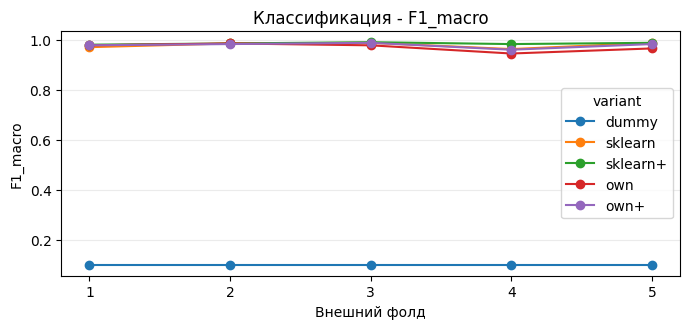


Регрессия - MAE
Эффект подбора sklearn: улучшение, Delta=+0.0693, выигрышей 3/5, проигрышей 1/5
Своя реализация против исходной sklearn: ухудшение, Delta=-0.0643, выигрышей 1/5, проигрышей 1/5
Своя реализация против настроенной sklearn: улучшение, Delta=+0.0469, выигрышей 2/5, проигрышей 0/5
Эффект переноса настроек на свою реализацию: улучшение, Delta=+0.1804, выигрышей 3/5, проигрышей 1/5


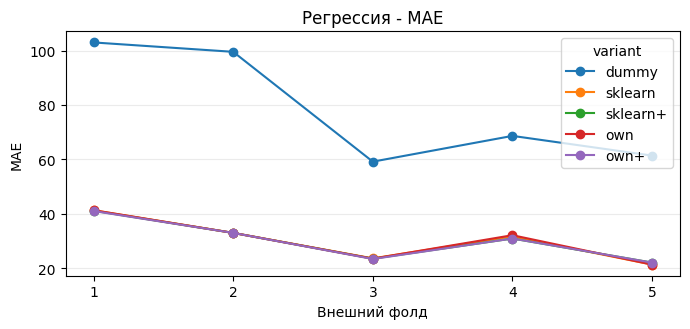

In [9]:
# считаем парные изменения метрики, чтобы сформулировать выводы по обеим задачам
comparisons = [
    ("sklearn+", "sklearn", "Эффект подбора sklearn"),
    ("own", "sklearn", "Своя реализация против исходной sklearn"),
    ("own+", "sklearn+", "Своя реализация против настроенной sklearn"),
    ("own+", "own", "Эффект переноса настроек на свою реализацию"),
]
for task in TASK_NAMES:
    metric = PRIMARY[task]
    values = results.loc[results["task"] == task].pivot(index="fold", columns="variant", values=metric)
    direction = 1 if task == "classification" else -1
    print(f"\n{TASK_NAMES[task]} - {metric}")
    for first, second, label in comparisons:
        gain = direction * (values[first] - values[second])
        mean = gain.mean()
        tendency = "улучшение" if mean > 1e-10 else "ухудшение" if mean < -1e-10 else "без изменений"
        wins = int((gain > 1e-10).sum())
        losses = int((gain < -1e-10).sum())
        print(f"{label}: {tendency}, Delta={mean:+.4f}, выигрышей {wins}/5, проигрышей {losses}/5")

    ax = values[VARIANTS].plot(marker="o", figsize=(7, 3.4), title=f"{TASK_NAMES[task]} - {metric}")
    ax.set(xlabel="Внешний фолд", ylabel=metric, xticks=values.index)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()